In [0]:
csv_path = "/Volumes/era5_project/raw/era5_files"

df_raw = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(csv_path)
)

print("Rows:", df_raw.count())
print("Columns:", len(df_raw.columns))

df_raw.printSchema()
display(df_raw.limit(10))

Rows: 507988
Columns: 7
root
 |-- Valid_time: string (nullable = true)
 |-- Pressure Level: integer (nullable = true)
 |-- Geopotential: double (nullable = true)
 |-- Relative Humidity: double (nullable = true)
 |-- Temperature: double (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)



Valid_time,Pressure Level,Geopotential,Relative Humidity,Temperature,latitude,longitude
1/01/2000 0:00,1000,742.0039,72.86274,294.68015,-36.75,174.75
1/01/2000 0:00,925,7303.4497,97.00138,288.02487,-36.75,174.75
1/01/2000 0:00,850,14285.859,83.205956,284.1772,-36.75,174.75
1/01/2000 0:00,700,29899.55,57.04135,273.3913,-36.75,174.75
1/01/2000 0:00,600,41893.16,21.778152,267.55777,-36.75,174.75
1/01/2000 0:00,500,55656.887,42.728226,257.56363,-36.75,174.75
1/01/2000 0:00,400,71803.875,38.95733,246.9512,-36.75,174.75
1/01/2000 0:00,300,91650.875,9.132197,234.95352,-36.75,174.75
1/01/2000 0:00,250,103841.375,4.7959237,230.73988,-36.75,174.75
1/01/2000 0:00,200,118408.69,5.3804083,224.43033,-36.75,174.75


In [0]:
from pyspark.sql import functions as F

# 1. Count total rows
total_rows = df_raw.count()

# 2. Check missing values in every column
missing_exprs = [
    F.sum(
        F.when(
            F.col(c).isNull() |
            (F.trim(F.col(c).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in df_raw.columns
]

missing_summary = df_raw.select(missing_exprs)

# 3. Display missing-value counts
print("Total rows:", total_rows)
print("Missing values by column:")
display(missing_summary)

# 4. Calculate missing-value percentages
missing_percentages = missing_summary.select([
    (
        F.col(c) / F.lit(total_rows) * 100
    ).alias(c)
    for c in df_raw.columns
])

print("Missing-value percentages (%):")
display(missing_percentages)

Total rows: 507988
Missing values by column:


Valid_time,Pressure Level,Geopotential,Relative Humidity,Temperature,latitude,longitude
0,0,0,0,0,0,0


Missing-value percentages (%):


Valid_time,Pressure Level,Geopotential,Relative Humidity,Temperature,latitude,longitude
0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [0]:
from pyspark.sql import functions as F

# Valid_time: string -> timestamp
df = df_raw.withColumn(
    "Valid_time",
    F.expr("try_to_timestamp(Valid_time, 'd/M/yyyy H:mm')")
)


df.printSchema()
display(df.limit(10))

bad_count = df.filter(F.col("Valid_time").isNull()).count() - df_raw.filter(F.col("Valid_time").isNull()).count()
print("Dòng lỗi định dạng:", bad_count)

root
 |-- Valid_time: timestamp (nullable = true)
 |-- Pressure Level: integer (nullable = true)
 |-- Geopotential: double (nullable = true)
 |-- Relative Humidity: double (nullable = true)
 |-- Temperature: double (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)



Valid_time,Pressure Level,Geopotential,Relative Humidity,Temperature,latitude,longitude
2000-01-01T00:00:00.000Z,1000,742.0039,72.86274,294.68015,-36.75,174.75
2000-01-01T00:00:00.000Z,925,7303.4497,97.00138,288.02487,-36.75,174.75
2000-01-01T00:00:00.000Z,850,14285.859,83.205956,284.1772,-36.75,174.75
2000-01-01T00:00:00.000Z,700,29899.55,57.04135,273.3913,-36.75,174.75
2000-01-01T00:00:00.000Z,600,41893.16,21.778152,267.55777,-36.75,174.75
2000-01-01T00:00:00.000Z,500,55656.887,42.728226,257.56363,-36.75,174.75
2000-01-01T00:00:00.000Z,400,71803.875,38.95733,246.9512,-36.75,174.75
2000-01-01T00:00:00.000Z,300,91650.875,9.132197,234.95352,-36.75,174.75
2000-01-01T00:00:00.000Z,250,103841.375,4.7959237,230.73988,-36.75,174.75
2000-01-01T00:00:00.000Z,200,118408.69,5.3804083,224.43033,-36.75,174.75


Dòng lỗi định dạng: 0


In [0]:
from pyspark.sql import functions as F

# 1. Chuẩn hóa tên cột: bỏ dấu cách, viết thường
df = df.toDF(*[c.strip().lower().replace(" ", "_") for c in df.columns])
# -> valid_time, pressure_level, geopotential, relative_humidity, temperature, latitude, longitude

# 2. Ép kiểu rõ ràng
df = (
    df
    .withColumn("pressure_level", F.col("pressure_level").cast("int"))
    .withColumn("geopotential", F.col("geopotential").cast("double"))
    .withColumn("relative_humidity", F.col("relative_humidity").cast("double"))
    .withColumn("temperature", F.col("temperature").cast("double"))
    .withColumn("latitude", F.col("latitude").cast("double"))
    .withColumn("longitude", F.col("longitude").cast("double"))
)

# 3. Quy đổi đơn vị (giữ cột gốc nếu muốn, ở đây thêm cột mới)
df = (
    df
    .withColumn("temperature_c", F.col("temperature") - 273.15)
    .withColumn("geopotential_height_m", F.col("geopotential") / 9.80665)
)

# 4. Kiểm tra chất lượng
df = df.dropDuplicates(["valid_time", "pressure_level", "latitude", "longitude"])

df.select(
    F.min("relative_humidity").alias("rh_min"), F.max("relative_humidity").alias("rh_max"),
    F.min("temperature_c").alias("t_min"), F.max("temperature_c").alias("t_max")
).show()

display(df.limit(10))

+----------+---------+------------------+------------------+
|    rh_min|   rh_max|             t_min|             t_max|
+----------+---------+------------------+------------------+
|-5.3504505|138.20152|-79.43211999999997|25.755460000000028|
+----------+---------+------------------+------------------+



valid_time,pressure_level,geopotential,relative_humidity,temperature,latitude,longitude,temperature_c,geopotential_height_m
2000-01-01T12:00:00.000Z,700,29865.586,36.79726,274.68002,-36.75,174.75,1.530020000000036,3045.4422254286633
2000-01-01T12:00:00.000Z,300,91958.31,14.784679,233.68431,-36.75,174.75,-39.46568999999997,9377.137962505036
2000-01-01T12:00:00.000Z,150,136592.44,4.848752,216.76363,-36.75,174.75,-56.38636999999997,13928.55256382149
2000-01-02T12:00:00.000Z,1000,691.7473,88.86223,289.4596,-36.75,174.75,16.309600000000046,70.53859370937069
2000-01-02T12:00:00.000Z,925,7145.2188,89.19455,284.51474,-36.75,174.75,11.36474000000004,728.6095455634697
2000-01-02T18:00:00.000Z,100,160713.31,6.1574097,209.5424,-36.75,174.75,-63.60759999999999,16388.19678483478
2000-01-03T18:00:00.000Z,150,135356.31,2.1437387,220.25763,-36.75,174.75,-52.89236999999997,13802.502383586649
2000-01-04T06:00:00.000Z,700,29176.879,37.93555,270.22485,-36.75,174.75,-2.9251499999999737,2975.2136560395243
2000-01-04T12:00:00.000Z,100,160463.75,6.189025,209.84145,-36.75,174.75,-63.30854999999997,16362.748747023705
2000-01-05T00:00:00.000Z,250,103380.125,37.95856,221.78758,-36.75,174.75,-51.362419999999986,10541.838956218486


In [0]:
df.write.format("delta").mode("overwrite").saveAsTable("era5_project.silver.era5_clean")

In [0]:

df_check = spark.table("era5_project.silver.era5_clean")
df_check.printSchema()
print("Rows:", df_check.count())
display(df_check.limit(10))

root
 |-- valid_time: timestamp (nullable = true)
 |-- pressure_level: integer (nullable = true)
 |-- geopotential: double (nullable = true)
 |-- relative_humidity: double (nullable = true)
 |-- temperature: double (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- temperature_c: double (nullable = true)
 |-- geopotential_height_m: double (nullable = true)

Rows: 507988


valid_time,pressure_level,geopotential,relative_humidity,temperature,latitude,longitude,temperature_c,geopotential_height_m
2000-01-01T12:00:00.000Z,700,29865.586,36.79726,274.68002,-36.75,174.75,1.530020000000036,3045.4422254286633
2000-01-01T12:00:00.000Z,300,91958.31,14.784679,233.68431,-36.75,174.75,-39.46568999999997,9377.137962505036
2000-01-01T12:00:00.000Z,150,136592.44,4.848752,216.76363,-36.75,174.75,-56.38636999999997,13928.55256382149
2000-01-02T12:00:00.000Z,1000,691.7473,88.86223,289.4596,-36.75,174.75,16.309600000000046,70.53859370937069
2000-01-02T12:00:00.000Z,925,7145.2188,89.19455,284.51474,-36.75,174.75,11.36474000000004,728.6095455634697
2000-01-02T18:00:00.000Z,100,160713.31,6.1574097,209.5424,-36.75,174.75,-63.60759999999999,16388.19678483478
2000-01-03T18:00:00.000Z,150,135356.31,2.1437387,220.25763,-36.75,174.75,-52.89236999999997,13802.502383586649
2000-01-04T06:00:00.000Z,700,29176.879,37.93555,270.22485,-36.75,174.75,-2.9251499999999737,2975.2136560395243
2000-01-04T12:00:00.000Z,100,160463.75,6.189025,209.84145,-36.75,174.75,-63.30854999999997,16362.748747023705
2000-01-05T00:00:00.000Z,250,103380.125,37.95856,221.78758,-36.75,174.75,-51.362419999999986,10541.838956218486


In [0]:
%sql
DESCRIBE DETAIL era5_project.silver.era5_clean;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,729a233a-835c-4b07-9ec9-1867cabacde7,era5_project.silver.era5_clean,"The table contains meteorological data related to various atmospheric parameters. It includes information such as temperature, pressure levels, geopotential height, and humidity, along with their corresponding geographical coordinates and timestamps. This data can be useful for climate analysis, weather prediction modeling, and studying atmospheric changes over time.",,2026-10-09T10:40:45.394Z,2026-10-30T07:56:28.000Z,List(),List(),1,15772092,"Map(delta.parquet.compression.codec -> zstd, delta.parquet.format.version.afe.internal -> 2.12.0, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, io.unitycatalog.tableId -> 906100e3-09d6-4955-843f-443447c68092)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:
%sql
SELECT COUNT(*) AS total_rows
FROM era5_project.silver.era5_clean;

total_rows
507988


In [0]:
%sql
SELECT
    pressure_level,
    AVG(temperature_c) AS avg_temperature_c
FROM era5_project.silver.era5_clean
GROUP BY pressure_level
ORDER BY pressure_level;

pressure_level,avg_temperature_c
50,-58.952393053024984
100,-61.24224860195457
150,-56.68771263512138
200,-53.75763440730857
250,-49.89305005502101
300,-42.94607341130116
400,-28.463245565052993
500,-16.725640787695752
600,-7.502565092383992
700,-0.35896334937043545


In [0]:
%sql
DESCRIBE DETAIL era5_project.silver.era5_clean;

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,729a233a-835c-4b07-9ec9-1867cabacde7,era5_project.silver.era5_clean,"The table contains meteorological data related to various atmospheric parameters. It includes information such as temperature, pressure levels, geopotential height, and humidity, along with their corresponding geographical coordinates and timestamps. This data can be useful for climate analysis, weather prediction modeling, and studying atmospheric changes over time.",,2026-10-09T10:40:45.394Z,2026-10-30T07:56:28.000Z,List(),List(),1,15772092,"Map(delta.parquet.compression.codec -> zstd, delta.parquet.format.version.afe.internal -> 2.12.0, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, io.unitycatalog.tableId -> 906100e3-09d6-4955-843f-443447c68092)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


In [0]:
display(dbutils.fs.ls("/Volumes/era5_project/raw/era5_files"))

path,name,size,modificationTime
dbfs:/Volumes/era5_project/raw/era5_files/ERA5.csv,ERA5.csv,32574585,1791537576000


In [0]:
from pyspark.sql import functions as F

df = spark.table("era5_project.silver.era5_clean")

df.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in df.columns
]).show(truncate=False)

+----------+--------------+------------+-----------------+-----------+--------+---------+-------------+---------------------+
|valid_time|pressure_level|geopotential|relative_humidity|temperature|latitude|longitude|temperature_c|geopotential_height_m|
+----------+--------------+------------+-----------------+-----------+--------+---------+-------------+---------------------+
|0         |0             |0           |0                |0          |0       |0        |0            |0                    |
+----------+--------------+------------+-----------------+-----------+--------+---------+-------------+---------------------+



In [0]:

# Load the cleaned ERA5 dataset from Delta Lake
df = spark.table("era5_project.silver.era5_clean")

# Select the columns required for the analysis
df_analysis = df.select(
    "pressure_level",
    "temperature_c"
)

display(df_analysis.limit(10))

pressure_level,temperature_c
700,1.530020000000036
300,-39.46568999999997
150,-56.38636999999997
1000,16.309600000000046
925,11.36474000000004
100,-63.60759999999999
150,-52.89236999999997
700,-2.9251499999999737
100,-63.30854999999997
250,-51.362419999999986


In [0]:
from pyspark.sql import functions as F
# Map: select the key and value needed for analysis
mapped_df = (
    df.select(
        F.col("pressure_level"),
        F.col("temperature_c")
    )
    .filter(
        F.col("pressure_level").isNotNull() &
        F.col("temperature_c").isNotNull()
    )
)
print(mapped_df)

DataFrame[pressure_level: int, temperature_c: double]


In [0]:

# Attempt to implement MapReduce using RDD APIs

try:
    data = [
        (1000, 15.0),
        (1000, 14.5),
        (850, 6.5),
        (850, 7.0)
    ]

    rdd = spark.sparkContext.parallelize(data)

    mapped_rdd = rdd.map(
        lambda row: (row[0], (row[1], 1))
    )

    reduced_rdd = mapped_rdd.reduceByKey(
        lambda a, b: (a[0] + b[0], a[1] + b[1])
    )

    result = reduced_rdd.mapValues(
        lambda x: x[0] / x[1]
    )

    print(result.collect())

except Exception as e:
    print("RDD-based MapReduce attempt failed.")
    print(type(e).__name__)
    print(str(e))


RDD-based MapReduce attempt failed.
PySparkAttributeError
[JVM_ATTRIBUTE_NOT_SUPPORTED] Attribute `sparkContext` is not available on Standard access mode or Serverless compute because it requires direct access to the Spark driver JVM. Switch to Dedicated access mode to use it.


In [0]:
# Reduce: aggregate temperature statistics by pressure level
result_df = (
    mapped_df
    .groupBy("pressure_level")
    .agg(
        F.sum("temperature_c").alias("total_temperature_c"),
        F.count("temperature_c").alias("observation_count"),
        F.avg("temperature_c").alias("average_temperature_c")
    )
    .orderBy("pressure_level")
)

display(result_df)

pressure_level,total_temperature_c,observation_count,average_temperature_c
50,-2303623.7109400043,39076,-58.952393053024984
100,-2393102.106369977,39076,-61.24224860195457
150,-2215129.058930003,39076,-56.68771263512138
200,-2100633.3220999897,39076,-53.75763440730857
250,-1949620.8239500008,39076,-49.89305005502101
300,-1678160.764620004,39076,-42.94607341130116
400,-1112229.7837000107,39076,-28.463245565052993
500,-653571.1394199992,39076,-16.725640787695752
600,-293170.23354999686,39076,-7.502565092383992
700,-14026.851839999135,39076,-0.35896334937043545


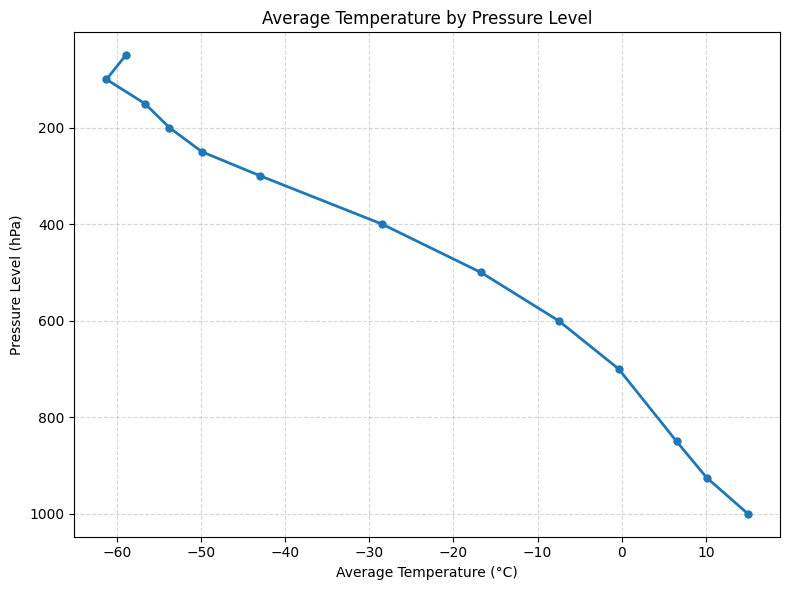

In [0]:
import matplotlib.pyplot as plt

# Prepare the results for visualization
plot_df = (
    result_df
    .select("pressure_level", "average_temperature_c")
    .orderBy("pressure_level")
    .toPandas()
)

# Create the line chart
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    plot_df["average_temperature_c"],
    plot_df["pressure_level"],
    marker="o",
    linewidth=2,
    markersize=5
)

# Display lower pressure levels at the top
ax.invert_yaxis()

ax.set_title("Average Temperature by Pressure Level")
ax.set_xlabel("Average Temperature (°C)")
ax.set_ylabel("Pressure Level (hPa)")

ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [0]:
from pyspark.sql import functions as F

df = spark.table("era5_project.silver.era5_clean")

# Map: select the required fields
mapped_df = (
    df.select(
        "pressure_level",
        "temperature_c",
        "geopotential_height_m"
    )
    .filter(
        F.col("pressure_level").isNotNull() &
        F.col("temperature_c").isNotNull() &
        F.col("geopotential_height_m").isNotNull()
    )
)

# Reduce: aggregate statistics by pressure level
result_df = (
    mapped_df
    .groupBy("pressure_level")
    .agg(
        F.sum("temperature_c").alias("total_temperature_c"),
        F.count("temperature_c").alias("observation_count"),
        F.avg("temperature_c").alias("average_temperature_c"),
        F.avg("geopotential_height_m").alias("average_geopotential_height_m")
    )
    .withColumn(
        "average_geopotential_height_km",
        F.col("average_geopotential_height_m") / 1000
    )
    .orderBy("pressure_level")
)

display(result_df)

pressure_level,total_temperature_c,observation_count,average_temperature_c,average_geopotential_height_m,average_geopotential_height_km
50,-2303623.7109400043,39076,-58.952393053024984,20645.520110636,20.645520110636
100,-2393102.106369977,39076,-61.24224860195457,16337.437039576276,16.337437039576276
150,-2215129.058930003,39076,-56.68771263512138,13798.542268127176,13.798542268127175
200,-2100633.3220999897,39076,-53.75763440730857,11962.382609170143,11.962382609170144
250,-1949620.8239500008,39076,-49.89305005502101,10519.18796058809,10.51918796058809
300,-1678160.764620004,39076,-42.94607341130116,9310.411384240242,9.310411384240242
400,-1112229.7837000107,39076,-28.463245565052993,7312.0681607042925,7.3120681607042926
500,-653571.1394199992,39076,-16.725640787695752,5674.831290306374,5.674831290306375
600,-293170.23354999686,39076,-7.502565092383992,4280.6786911701965,4.280678691170197
700,-14026.851839999135,39076,-0.35896334937043545,3064.419306086544,3.064419306086544


In [0]:
from pyspark.sql import functions as F

# Load the cleaned ERA5 Delta table
df = spark.table("era5_project.silver.era5_clean")

# Filter pressure level at 1000 hPa
# Convert UTC timestamps to Auckland local time
monthly_temp_df = (
    df
    .filter(F.col("pressure_level") == 1000)
    .withColumn(
        "local_time",
        F.from_utc_timestamp(
            F.col("valid_time"),
            "Pacific/Auckland"
        )
    )
    .withColumn("month_num", F.month("local_time"))
    .groupBy("month_num")
    .agg(
        F.avg("temperature_c").alias("average_temperature_c"),
        F.count("*").alias("observation_count")
    )
    .orderBy("month_num")
)

display(monthly_temp_df)

month_num,average_temperature_c,observation_count
1,18.489882875074716,3346
2,19.00061265072089,3052
3,17.83817780764634,3348
4,16.32165013580251,3240
5,14.488874677419375,3348
6,12.734389885802488,3240
7,11.699820209080102,3348
8,11.633149118876979,3348
9,12.414298823347758,3238
10,13.42021569789082,3224


Databricks visualization. Run in Databricks to view.

In [0]:
from pyspark.sql import functions as F

df = spark.table("era5_project.silver.era5_clean")

annual_weather_df = (
    df
    .filter(F.col("pressure_level") == 1000)
    .withColumn(
        "local_time",
        F.from_utc_timestamp(
            F.col("valid_time"),
            "Pacific/Auckland"
        )
    )
    .withColumn("year", F.year("local_time"))
    .filter(F.col("year").between(2000, 2026))
    .groupBy("year")
    .agg(
        F.avg("temperature_c").alias("average_temperature_c"),
        F.avg("relative_humidity").alias("average_relative_humidity"),
        F.count("*").alias("observation_count")
    )
    .orderBy("year")
)

display(annual_weather_df)

year,average_temperature_c,average_relative_humidity,observation_count
2000,14.684804596443254,75.40472383173747,1462
2001,14.8313331712329,76.98314746917787,1460
2002,14.742232623287693,74.90822423767128,1460
2003,14.753135075342502,76.26657892671231,1460
2004,14.189053114754119,75.31607107240454,1464
2005,15.143824835616451,75.56624268835614,1460
2006,14.488680493150706,75.42485930410973,1460
2007,14.795400486301384,76.46012504041096,1460
2008,14.876072247267805,75.76778049112019,1464
2009,14.4639212945206,75.2636371952054,1460


Databricks visualization. Run in Databricks to view.

Databricks visualization. Run in Databricks to view.

In [0]:

from pyspark.sql import functions as F
import time
import statistics

table_name = "era5_project.silver.era5_clean"

def run_profile_query():
    return (
        spark.table(table_name)
        .select(
            "pressure_level",
            "temperature_c",
            "geopotential_height_m"
        )
        .filter(
            F.col("pressure_level").isNotNull()
            & F.col("temperature_c").isNotNull()
            & F.col("geopotential_height_m").isNotNull()
        )
        .groupBy("pressure_level")
        .agg(
            F.count("temperature_c").alias("observation_count"),
            F.avg("temperature_c").alias("average_temperature_c"),
            F.avg("geopotential_height_m").alias(
                "average_geopotential_height_m"
            )
        )
        .orderBy("pressure_level")
    )

# Warm-up run
run_profile_query().collect()

# Record five runs
times = []

for i in range(5):
    start = time.perf_counter()
    result = run_profile_query().collect()
    elapsed = time.perf_counter() - start

    times.append(elapsed)
    print(f"Run {i + 1}: {elapsed:.3f} seconds")

print(f"Median runtime: {statistics.median(times):.3f} seconds")
print(f"Output rows: {len(result)}")


Run 1: 0.507 seconds
Run 2: 0.523 seconds
Run 3: 0.510 seconds
Run 4: 0.491 seconds
Run 5: 0.491 seconds
Median runtime: 0.507 seconds
Output rows: 13


In [0]:

from pyspark.sql import functions as F

source_table = "era5_project.silver.era5_clean"
tempreture_table = "era5_project.silver.era5_profile_tempreture"

# Build the same aggregation as the original query
summary_df = (
    spark.table(source_table)
    .select(
        "pressure_level",
        "temperature_c",
        "geopotential_height_m"
    )
    .filter(
        F.col("pressure_level").isNotNull()
        & F.col("temperature_c").isNotNull()
        & F.col("geopotential_height_m").isNotNull()
    )
    .groupBy("pressure_level")
    .agg(
        F.count("temperature_c").alias("observation_count"),
        F.avg("temperature_c").alias("average_temperature_c"),
        F.avg("geopotential_height_m").alias(
            "average_geopotential_height_m"
        )
    )
    .withColumn(
        "average_geopotential_height_km",
        F.col("average_geopotential_height_m") / 1000
    )
)

# Save to a separate test table; keep the original Silver table unchanged
(
    summary_df.write
    .format("delta")
    .mode("overwrite")
    .saveAsTable(tempreture_table)
)

print("Created tempreture table:", tempreture_table)
print("Summary rows:", spark.table(tempreture_table).count())


Created tempreture table: era5_project.silver.era5_profile_tempreture
Summary rows: 13


In [0]:

from pyspark.sql import functions as F
import time
import statistics

source_table = "era5_project.silver.era5_clean"

# Change this to the exact catalog.schema.table name
# shown in Catalog Explorer for your summary table.
summary_table = "era5_project.silver.era5_profile_tempreture"


# A: calculate the aggregation from detailed records
def query_before():
    return (
        spark.table(source_table)
        .select(
            "pressure_level",
            "temperature_c",
            "geopotential_height_m"
        )
        .filter(
            F.col("pressure_level").isNotNull()
            & F.col("temperature_c").isNotNull()
            & F.col("geopotential_height_m").isNotNull()
        )
        .groupBy("pressure_level")
        .agg(
            F.count("temperature_c").alias("observation_count"),
            F.avg("temperature_c").alias("average_temperature_c"),
            F.avg("geopotential_height_m").alias(
                "average_geopotential_height_m"
            )
        )
        .withColumn(
            "average_geopotential_height_km",
            F.col("average_geopotential_height_m") / 1000
        )
        .orderBy("pressure_level")
    )


# B: read the pre-aggregated result
def query_after():
    return (
        spark.table(summary_table)
        .select(
            "pressure_level",
            "observation_count",
            "average_temperature_c",
            "average_geopotential_height_m",
            "average_geopotential_height_km"
        )
        .orderBy("pressure_level")
    )


def benchmark(query_function, repeats=5):
    times = []

    for i in range(repeats):
        start = time.perf_counter()
        rows = query_function().collect()
        elapsed = time.perf_counter() - start

        times.append(elapsed)
        print(f"Run {i + 1}: {elapsed:.3f} seconds")

    return statistics.median(times)


# Warm up both paths
query_before().collect()
query_after().collect()

print("BEFORE: aggregate detailed Silver data")
before_median = benchmark(query_before)

print("\nAFTER: read pre-aggregated Delta table")
after_median = benchmark(query_after)

print(f"\nBefore median: {before_median:.3f} seconds")
print(f"After median:  {after_median:.3f} seconds")

if before_median > 0:
    reduction_pct = (
        (before_median - after_median) / before_median
    ) * 100
    print(f"Runtime reduction: {reduction_pct:.2f}%")


BEFORE: aggregate detailed Silver data
Run 1: 0.579 seconds
Run 2: 0.529 seconds
Run 3: 0.509 seconds
Run 4: 0.578 seconds
Run 5: 0.556 seconds

AFTER: read pre-aggregated Delta table
Run 1: 0.458 seconds
Run 2: 0.452 seconds
Run 3: 0.444 seconds
Run 4: 0.565 seconds
Run 5: 0.657 seconds

Before median: 0.556 seconds
After median:  0.458 seconds
Runtime reduction: 17.58%


In [0]:
from pyspark.sql import functions as F

df = spark.table("era5_project.silver.era5_clean").select(
    "valid_time",
    "geopotential_height_m",
    "temperature_c",
    "relative_humidity",
    "pressure_level"
)

current_df = df.withColumn(
    "target_time",
    F.expr("valid_time + INTERVAL 24 HOURS")
)

future_df = df.select(
    F.col("valid_time").alias("future_time"),
    F.col("pressure_level").alias("future_pressure_level"),
    F.col("temperature_c").alias("target_temperature_c")
)

ml_df = (
    current_df.join(
        future_df,
        (current_df["target_time"] == future_df["future_time"]) &
        (current_df["pressure_level"] == future_df["future_pressure_level"]),
        "inner"
    )
    .select(
        current_df["valid_time"],
        current_df["target_time"],
        current_df["geopotential_height_m"],
        current_df["temperature_c"],
        current_df["relative_humidity"],
        current_df["pressure_level"],
        future_df["target_temperature_c"]
    )
)

print("Rows available for ML:", ml_df.count())
display(ml_df.limit(10))

Rows available for ML: 507936


valid_time,target_time,geopotential_height_m,temperature_c,relative_humidity,pressure_level,target_temperature_c
2000-01-06T00:00:00.000Z,2000-01-07T00:00:00.000Z,9377.361280355677,-42.401749999999964,70.96052,300,-42.71113999999997
2000-03-26T06:00:00.000Z,2000-03-27T06:00:00.000Z,3094.96739457409,0.5144300000000044,67.045616,700,0.9582200000000398
2000-04-25T18:00:00.000Z,2000-04-26T18:00:00.000Z,16113.147710992032,-58.81335999999999,3.1007595,100,-63.33625999999998
2000-05-12T12:00:00.000Z,2000-05-13T12:00:00.000Z,13837.364441475938,-55.63769999999997,5.0496807,150,-56.333939999999984
2000-05-18T18:00:00.000Z,2000-05-19T18:00:00.000Z,843.7027935125654,7.8146600000000035,80.11016,925,9.051870000000008
2000-05-26T18:00:00.000Z,2000-05-27T18:00:00.000Z,3135.2760626717586,-1.19144,6.3972197,700,0.08383000000003449
2000-08-03T18:00:00.000Z,2000-08-04T18:00:00.000Z,1489.2679967165138,0.94106000000005,91.92474,850,0.3106999999999971
2000-08-07T18:00:00.000Z,2000-08-08T18:00:00.000Z,892.3384642054117,4.148800000000051,75.13922,925,4.2275000000000205
2000-12-27T18:00:00.000Z,2000-12-28T18:00:00.000Z,9516.278239765874,-35.49389999999997,91.27367,300,-31.53959999999998
2001-01-04T18:00:00.000Z,2001-01-05T18:00:00.000Z,3156.4152896248975,2.2446500000000356,12.8587055,700,1.7667000000000144


In [0]:
from pyspark.ml.feature import VectorAssembler

feature_cols = [
    "geopotential_height_m",
    "temperature_c",
    "relative_humidity",
    "pressure_level"
]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

model_df = assembler.transform(ml_df).select(
    "valid_time",
    "target_time",
    "features",
    "target_temperature_c"
)

display(model_df.limit(10))

valid_time,target_time,features,target_temperature_c
2000-01-01T12:00:00.000Z,2000-01-02T12:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""3045.4422254286633"",""1.530020000000036"",""36.79726"",""700.0""]}",3.231840000000034
2000-01-01T12:00:00.000Z,2000-01-02T12:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""9377.137962505036"",""-39.46568999999997"",""14.784679"",""300.0""]}",-38.47934999999998
2000-01-01T12:00:00.000Z,2000-01-02T12:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""13928.55256382149"",""-56.38636999999997"",""4.848752"",""150.0""]}",-57.810479999999984
2000-01-02T12:00:00.000Z,2000-01-03T12:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""70.53859370937069"",""16.309600000000046"",""88.86223"",""1000.0""]}",15.436360000000036
2000-01-02T12:00:00.000Z,2000-01-03T12:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""728.6095455634697"",""11.36474000000004"",""89.19455"",""925.0""]}",9.379750000000001
2000-01-02T18:00:00.000Z,2000-01-03T18:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""16388.19678483478"",""-63.60759999999999"",""6.1574097"",""100.0""]}",-61.69456999999997
2000-01-03T18:00:00.000Z,2000-01-04T18:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""13802.502383586649"",""-52.89236999999997"",""2.1437387"",""150.0""]}",-56.545229999999975
2000-01-04T06:00:00.000Z,2000-01-05T06:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""2975.2136560395243"",""-2.9251499999999737"",""37.93555"",""700.0""]}",2.036580000000015
2000-01-04T12:00:00.000Z,2000-01-05T12:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""16362.748747023705"",""-63.30854999999997"",""6.189025"",""100.0""]}",-63.72786999999997
2000-01-05T00:00:00.000Z,2000-01-06T00:00:00.000Z,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""10541.838956218486"",""-51.362419999999986"",""37.95856"",""250.0""]}",-51.65229999999997


In [0]:
# Calculate the chronological cutoff at 80% of the time range
time_range = ml_df.agg(
    F.min("valid_time").alias("min_time"),
    F.max("valid_time").alias("max_time")
).first()

min_time = time_range["min_time"]
max_time = time_range["max_time"]

cutoff_seconds = (
    max_time.timestamp() - min_time.timestamp()
) * 0.8

from datetime import timedelta

cutoff_time = min_time + timedelta(seconds=cutoff_seconds)

# Training targets must occur before the cutoff
train_df = model_df.filter(
    F.col("target_time") < F.lit(cutoff_time)
)

# Test observations begin at or after the cutoff
test_df = model_df.filter(
    F.col("valid_time") >= F.lit(cutoff_time)
)

print("Cutoff time:", cutoff_time)
print("Training rows:", train_df.count())
print("Testing rows:", test_df.count())

Cutoff time: 2021-05-24 04:48:00
Training rows: 406289
Testing rows: 101595


In [0]:
from pyspark.ml.regression import DecisionTreeRegressor

dt = DecisionTreeRegressor(
    featuresCol="features",
    labelCol="target_temperature_c",
    predictionCol="prediction",
    maxDepth=10,
    minInstancesPerNode=50,
    seed=42
)

dt_model = dt.fit(train_df)

predictions = dt_model.transform(test_df)

display(
    predictions.select(
        "valid_time",
        "target_time",
        "target_temperature_c",
        "prediction"
    )
)

valid_time,target_time,target_temperature_c,prediction
2021-07-03T00:00:00.000Z,2021-07-04T00:00:00.000Z,-56.23315999999997,-54.01694996823714
2021-07-06T12:00:00.000Z,2021-07-07T12:00:00.000Z,-57.543589999999966,-52.19904373401534
2021-09-29T18:00:00.000Z,2021-09-30T18:00:00.000Z,-54.43769999999998,-54.59678303066035
2021-10-20T06:00:00.000Z,2021-10-21T06:00:00.000Z,-45.13599999999997,-48.12051758278144
2021-11-10T12:00:00.000Z,2021-11-11T12:00:00.000Z,-57.80869999999999,-57.69341810246677
2021-11-27T06:00:00.000Z,2021-11-28T06:00:00.000Z,-11.331799999999987,-10.283065580389305
2021-12-12T18:00:00.000Z,2021-12-13T18:00:00.000Z,-60.66002999999998,-60.77155327562795
2021-12-17T18:00:00.000Z,2021-12-18T18:00:00.000Z,-4.099829999999997,-6.837596838124032
2022-01-10T00:00:00.000Z,2022-01-11T00:00:00.000Z,-39.717059999999975,-34.74563696696694
2022-01-12T12:00:00.000Z,2022-01-13T12:00:00.000Z,6.250400000000013,6.599283296703319


In [0]:
from pyspark.ml.evaluation import RegressionEvaluator

mae_evaluator = RegressionEvaluator(
    labelCol="target_temperature_c",
    predictionCol="prediction",
    metricName="mae"
)

rmse_evaluator = RegressionEvaluator(
    labelCol="target_temperature_c",
    predictionCol="prediction",
    metricName="rmse"
)

r2_evaluator = RegressionEvaluator(
    labelCol="target_temperature_c",
    predictionCol="prediction",
    metricName="r2"
)

mae = mae_evaluator.evaluate(predictions)
rmse = rmse_evaluator.evaluate(predictions)
r2 = r2_evaluator.evaluate(predictions)

print(f"MAE:  {mae:.4f} °C")
print(f"RMSE: {rmse:.4f} °C")
print(f"R²:   {r2:.4f}")

MAE:  1.9554 °C
RMSE: 2.5981 °C
R²:   0.9914


In [0]:
from pyspark.ml.regression import DecisionTreeRegressor
from pyspark.ml.evaluation import RegressionEvaluator

configs = [
    (20,50),
    (3, 20),
    (8,50),
    (5, 20),
    (5, 50),
    (7, 20),
    (7, 50),
    (10, 50)
]

mae_eval = RegressionEvaluator(
    labelCol="target_temperature_c",
    predictionCol="prediction",
    metricName="mae"
)

rmse_eval = RegressionEvaluator(
    labelCol="target_temperature_c",
    predictionCol="prediction",
    metricName="rmse"
)

r2_eval = RegressionEvaluator(
    labelCol="target_temperature_c",
    predictionCol="prediction",
    metricName="r2"
)

results = []

for depth, min_node in configs:
    model = DecisionTreeRegressor(
        featuresCol="features",
        labelCol="target_temperature_c",
        maxDepth=depth,
        minInstancesPerNode=min_node
    )

    fitted_model = model.fit(train_df)
    validation_predictions = fitted_model.transform(test_df)

    results.append((
        depth,
        min_node,
        mae_eval.evaluate(validation_predictions),
        rmse_eval.evaluate(validation_predictions),
        r2_eval.evaluate(validation_predictions)
    ))

results_df = spark.createDataFrame(
    results,
    [
        "maxDepth",
        "minInstancesPerNode",
        "MAE",
        "RMSE",
        "R2"
    ]
)

display(results_df.orderBy("MAE"))

maxDepth,minInstancesPerNode,MAE,RMSE,R2
10,50,1.9543616784138724,2.600441811548319,0.991414540967384
20,50,1.954768984312132,2.601595512868154,0.9914069212986099
8,50,1.965414027870089,2.6132804687149953,0.9913295570521146
7,50,1.9907352586600187,2.646408243117016,0.9911083385021094
7,20,1.9908149326204236,2.6460765317380774,0.9911105673951423
5,50,2.1606968021585713,2.8625640225492535,0.989596495557435
5,20,2.160696802158579,2.8625640225492535,0.989596495557435
3,20,3.3083914715088447,4.117417856494693,0.9784761911266561


In [0]:
from pyspark.sql import functions as F

# Find the time range
time_range = ml_df.agg(
    F.min("valid_time").alias("min_time"),
    F.max("valid_time").alias("max_time")
).first()

min_time = time_range["min_time"]
max_time = time_range["max_time"]

# Use the first 80% of the time range for training
from datetime import timedelta

cutoff_time = min_time + timedelta(
    seconds=(max_time - min_time).total_seconds() * 0.8
)

# Keep training labels before the cutoff
train_raw = ml_df.filter(
    F.col("target_time") < F.lit(cutoff_time)
)

# Keep test observations from the cutoff onward
test_raw = ml_df.filter(
    F.col("valid_time") >= F.lit(cutoff_time)
)

print("Start time:", min_time)
print("End time:", max_time)
print("Cutoff time:", cutoff_time)
print("Training rows:", train_raw.count())
print("Testing rows:", test_raw.count())

Start time: 2000-01-01 00:00:00
End time: 2026-09-28 18:00:00
Cutoff time: 2021-05-24 04:48:00
Training rows: 406289
Testing rows: 101595


In [0]:
from pyspark.sql import functions as F

# Calculate classification thresholds from training data only
thresholds = (
    train_raw
    .groupBy("pressure_level")
    .agg(
        F.expr(
            "percentile_approx(target_temperature_c, 0.33)"
        ).alias("low_threshold"),
        F.expr(
            "percentile_approx(target_temperature_c, 0.67)"
        ).alias("high_threshold")
    )
)

display(thresholds.orderBy("pressure_level"))

pressure_level,low_threshold,high_threshold
50,-60.60725999999997,-57.60630999999998
100,-63.644799999999975,-58.66973999999999
150,-58.84732999999997,-54.60356999999999
200,-56.34394999999998,-51.50160999999997
250,-52.17457999999996,-48.267259999999965
300,-45.597339999999974,-40.99363999999997
400,-31.29509999999999,-25.85594999999998
500,-19.312769999999972,-14.151700000000005
600,-9.89749999999998,-5.053380000000004
700,-2.630799999999965,1.8804600000000278


In [0]:
from pyspark.sql import functions as F

# Join the same training-derived thresholds to both datasets
train_class = train_raw.join(
    thresholds,
    on="pressure_level",
    how="left"
)

test_class = test_raw.join(
    thresholds,
    on="pressure_level",
    how="left"
)

# Create classification labels
def add_temperature_label(df):
    return df.withColumn(
        "temperature_label",
        F.when(
            F.col("target_temperature_c") <= F.col("low_threshold"),
            "Low"
        ).when(
            F.col("target_temperature_c") <= F.col("high_threshold"),
            "Medium"
        ).otherwise("High")
    )

train_class = add_temperature_label(train_class)
test_class = add_temperature_label(test_class)

# Inspect the results
display(
    train_class.select(
        "valid_time",
        "target_time",
        "pressure_level",
        "target_temperature_c",
        "temperature_label"
    )
)

valid_time,target_time,pressure_level,target_temperature_c,temperature_label
2000-06-19T18:00:00.000Z,2000-06-20T18:00:00.000Z,300,-44.469179999999966,Medium
2000-09-10T12:00:00.000Z,2000-09-11T12:00:00.000Z,300,-46.08621999999997,Low
2001-02-09T06:00:00.000Z,2001-02-10T06:00:00.000Z,300,-29.84964999999997,High
2001-02-28T18:00:00.000Z,2001-03-01T18:00:00.000Z,300,-39.12587999999997,High
2001-07-07T12:00:00.000Z,2001-07-08T12:00:00.000Z,300,-45.86734999999999,Low
2000-07-24T06:00:00.000Z,2000-07-25T06:00:00.000Z,300,-49.318929999999966,Low
2000-01-16T00:00:00.000Z,2000-01-17T00:00:00.000Z,300,-42.04048999999998,Medium
2000-05-14T06:00:00.000Z,2000-05-15T06:00:00.000Z,300,-38.117879999999985,High
2001-01-28T12:00:00.000Z,2001-01-29T12:00:00.000Z,300,-39.02926999999997,High
2001-06-06T06:00:00.000Z,2001-06-07T06:00:00.000Z,300,-50.41963999999999,Low


In [0]:
display(
    train_class
    .groupBy("temperature_label")
    .count()
    .orderBy("temperature_label")
)

temperature_label,count
High,134090
Low,134063
Medium,138136


In [0]:
display(
    train_class
    .groupBy("pressure_level", "temperature_label")
    .count()
    .orderBy("pressure_level", "temperature_label")
)

pressure_level,temperature_label,count
50,High,10315
50,Low,10313
50,Medium,10625
100,High,10315
100,Low,10311
100,Medium,10627
150,High,10313
150,Low,10313
150,Medium,10627
200,High,10315


In [0]:
from pyspark.ml.feature import StringIndexer, VectorAssembler

# Convert class labels into numeric labels
label_indexer = StringIndexer(
    inputCol="temperature_label",
    outputCol="label",
    stringOrderType="alphabetAsc"
)

label_model = label_indexer.fit(train_class)

train_indexed = label_model.transform(train_class)
test_indexed = label_model.transform(test_class)

# Combine input features into a feature vector
feature_cols = [
    "temperature_c",
    "relative_humidity",
    "geopotential_height_m",
    "pressure_level"
]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

train_ml = assembler.transform(train_indexed).select(
    "valid_time",
    "target_time",
    "pressure_level",
    "temperature_label",
    "label",
    "features"
)

test_ml = assembler.transform(test_indexed).select(
    "valid_time",
    "target_time",
    "pressure_level",
    "temperature_label",
    "label",
    "features"
)

display(train_ml.limit(10))

valid_time,target_time,pressure_level,temperature_label,label,features
2001-12-26T12:00:00.000Z,2001-12-27T12:00:00.000Z,300,High,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-37.56019999999998"",""101.9946"",""9375.94642411017"",""300.0""]}"
2001-01-04T18:00:00.000Z,2001-01-05T18:00:00.000Z,700,Medium,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""2.2446500000000356"",""12.8587055"",""3156.4152896248975"",""700.0""]}"
2001-07-13T12:00:00.000Z,2001-07-14T12:00:00.000Z,50,High,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-58.45474999999999"",""1.4456176"",""20477.794149888086"",""50.0""]}"
2001-09-30T06:00:00.000Z,2001-10-01T06:00:00.000Z,850,Medium,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""4.935270000000003"",""78.63851"",""1599.4292648355963"",""850.0""]}"
2002-04-01T06:00:00.000Z,2002-04-02T06:00:00.000Z,850,Low,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""2.6736000000000217"",""45.76049"",""1414.5567038693132"",""850.0""]}"
2000-08-07T18:00:00.000Z,2000-08-08T18:00:00.000Z,925,Low,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""4.148800000000051"",""75.13922"",""892.3384642054117"",""925.0""]}"
2001-08-18T18:00:00.000Z,2001-08-19T18:00:00.000Z,925,Low,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""7.618070000000046"",""79.35598"",""671.8945817379024"",""925.0""]}"
2000-04-25T18:00:00.000Z,2000-04-26T18:00:00.000Z,100,Medium,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-58.81335999999999"",""3.1007595"",""16113.147710992032"",""100.0""]}"
2000-05-12T12:00:00.000Z,2000-05-13T12:00:00.000Z,150,Medium,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-55.63769999999997"",""5.0496807"",""13837.364441475938"",""150.0""]}"
2001-04-29T18:00:00.000Z,2001-04-30T18:00:00.000Z,150,Low,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""-61.36540999999997"",""8.71441"",""13850.436183610103"",""150.0""]}"


In [0]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    predictionCol="prediction",
    numTrees=100,
    maxDepth=10,
    minInstancesPerNode=100,
    seed=42
)

rf_model = rf.fit(train_ml)

predictions_rf = rf_model.transform(test_ml)

display(
    predictions_rf.select(
        "valid_time",
        "target_time",
        "pressure_level",
        "temperature_label",
        "label",
        "prediction",
        "probability"
    )
)

valid_time,target_time,pressure_level,temperature_label,label,prediction,probability
2021-05-24T18:00:00.000Z,2021-05-25T18:00:00.000Z,1000,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.026419167025263982"",""0.7494496179886763"",""0.2241312149860598""]}"
2021-05-25T00:00:00.000Z,2021-05-26T00:00:00.000Z,925,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.14374830716565373"",""0.51093974237921"",""0.3453119504551363""]}"
2021-05-26T18:00:00.000Z,2021-05-27T18:00:00.000Z,50,High,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6333030754572031"",""0.01898770358057207"",""0.34770922096222473""]}"
2021-05-27T00:00:00.000Z,2021-05-28T00:00:00.000Z,700,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.23057652272370405"",""0.38992969118532983"",""0.3794937860909661""]}"
2021-05-28T06:00:00.000Z,2021-05-29T06:00:00.000Z,150,High,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7739258737529605"",""0.03405366673073817"",""0.1920204595163013""]}"
2021-05-29T18:00:00.000Z,2021-05-30T18:00:00.000Z,925,Medium,2.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.12178839262236528"",""0.4989352424336539"",""0.37927636494398087""]}"
2021-05-30T12:00:00.000Z,2021-05-31T12:00:00.000Z,700,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.19790242035043587"",""0.4757872807492124"",""0.3263102989003518""]}"
2021-05-31T12:00:00.000Z,2021-06-01T12:00:00.000Z,925,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.12023742166024343"",""0.5065343412592308"",""0.3732282370805259""]}"
2021-06-01T18:00:00.000Z,2021-06-02T18:00:00.000Z,100,High,0.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.3187727588380867"",""0.10841732527078468"",""0.5728099158911287""]}"
2021-06-02T12:00:00.000Z,2021-06-03T12:00:00.000Z,250,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.14203445567602607"",""0.5813061701396419"",""0.27665937418433206""]}"


In [0]:
from pyspark.ml.classification import RandomForestClassifier

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    predictionCol="prediction",
    numTrees=100,
    maxDepth=10,
    minInstancesPerNode=100,
    seed=42
)

rf_model = rf.fit(train_ml)

predictions_rf = rf_model.transform(test_ml)

display(
    predictions_rf.select(
        "valid_time",
        "target_time",
        "pressure_level",
        "temperature_label",
        "label",
        "prediction",
        "probability"
    )
)

valid_time,target_time,pressure_level,temperature_label,label,prediction,probability
2021-05-24T18:00:00.000Z,2021-05-25T18:00:00.000Z,1000,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.026419167025263982"",""0.7494496179886763"",""0.2241312149860598""]}"
2021-05-25T00:00:00.000Z,2021-05-26T00:00:00.000Z,925,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.14374830716565373"",""0.51093974237921"",""0.3453119504551363""]}"
2021-05-26T18:00:00.000Z,2021-05-27T18:00:00.000Z,50,High,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.6333030754572031"",""0.01898770358057207"",""0.34770922096222473""]}"
2021-05-27T00:00:00.000Z,2021-05-28T00:00:00.000Z,700,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.23057652272370405"",""0.38992969118532983"",""0.3794937860909661""]}"
2021-05-28T06:00:00.000Z,2021-05-29T06:00:00.000Z,150,High,0.0,0.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.7739258737529605"",""0.03405366673073817"",""0.1920204595163013""]}"
2021-05-29T18:00:00.000Z,2021-05-30T18:00:00.000Z,925,Medium,2.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.12178839262236528"",""0.4989352424336539"",""0.37927636494398087""]}"
2021-05-30T12:00:00.000Z,2021-05-31T12:00:00.000Z,700,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.19790242035043587"",""0.4757872807492124"",""0.3263102989003518""]}"
2021-05-31T12:00:00.000Z,2021-06-01T12:00:00.000Z,925,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.12023742166024343"",""0.5065343412592308"",""0.3732282370805259""]}"
2021-06-01T18:00:00.000Z,2021-06-02T18:00:00.000Z,100,High,0.0,2.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.3187727588380867"",""0.10841732527078468"",""0.5728099158911287""]}"
2021-06-02T12:00:00.000Z,2021-06-03T12:00:00.000Z,250,Low,1.0,1.0,"{""type"":""1"",""size"":null,""indices"":null,""values"":[""0.14203445567602607"",""0.5813061701396419"",""0.27665937418433206""]}"


In [0]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

metric_names = [
    "accuracy",
    "weightedPrecision",
    "weightedRecall",
    "f1"
]

for metric_name in metric_names:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric_name
    )

    score = evaluator.evaluate(predictions_rf)
    print(f"{metric_name}: {score:.4f}")

accuracy: 0.6731
weightedPrecision: 0.6674
weightedRecall: 0.6731
f1: 0.6675


In [0]:
from pyspark.sql import functions as F

confusion_matrix = (
    predictions_rf
    .groupBy("label", "prediction")
    .count()
    .orderBy("label", "prediction")
)

display(confusion_matrix)

label,prediction,count
0.0,0.0,28367
0.0,1.0,1718
0.0,2.0,7001
1.0,0.0,928
1.0,1.0,23962
1.0,2.0,5606
2.0,0.0,7754
2.0,1.0,10209
2.0,2.0,16050


In [0]:
display(
    predictions.select(
        "target_temperature_c",
        "prediction"
    )
)

target_temperature_c,prediction
9.751300000000015,9.998525838926199
7.070340000000044,7.771734099709608
-55.33995999999999,-55.18472155213268
-3.6065999999999576,-3.1584240657697835
-48.09362999999999,-50.421387618097114
8.48397,8.049559095022648
-4.0811199999999985,-3.1584240657697835
7.853420000000028,7.771734099709608
-59.68567999999999,-57.69341810246677
-58.03413999999998,-54.64610904761903


Databricks visualization. Run in Databricks to view.

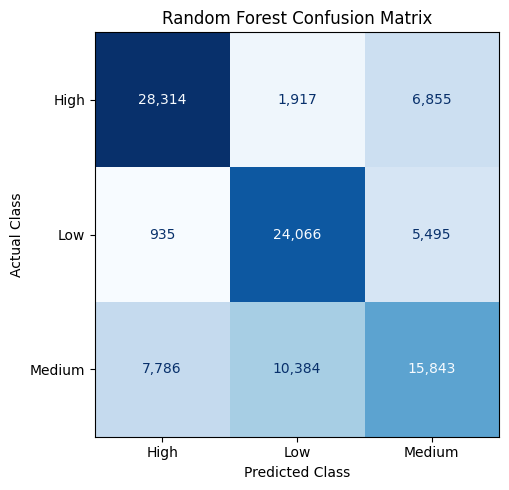

In [0]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Use Random Forest test predictions
pdf_rf = predictions_rf.select(
    "label", "prediction"
).toPandas()

# LabelIndexer uses alphabetic order:
# High = 0, Low = 1, Medium = 2
class_order = [0.0, 1.0, 2.0]
class_names = ["High", "Low", "Medium"]

cm = confusion_matrix(
    pdf_rf["label"],
    pdf_rf["prediction"],
    labels=class_order
)

fig, ax = plt.subplots(figsize=(7, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format=",",
    colorbar=False
)

ax.set_title("Random Forest Confusion Matrix")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

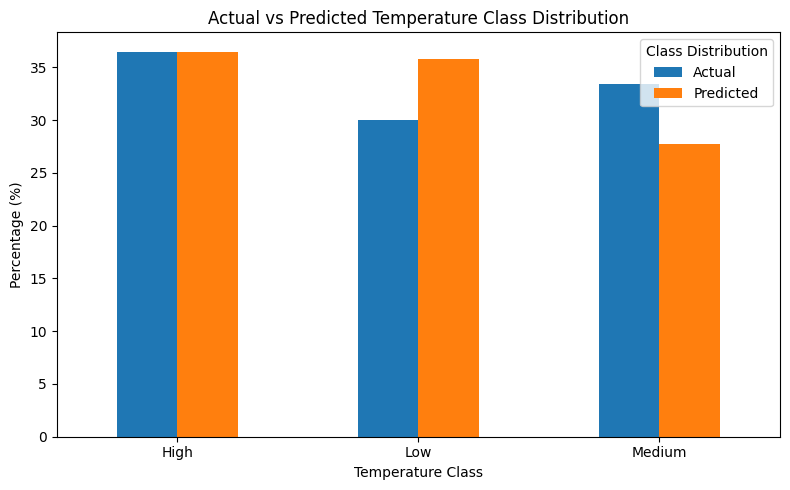

Actual,Predicted
36.5,36.45
30.02,35.8
33.48,27.75


In [0]:
import matplotlib.pyplot as plt
import pandas as pd

class_order = [0.0, 1.0, 2.0]
class_names = ["High", "Low", "Medium"]

# Actual class distribution
actual_dist = (
    pdf_rf["label"]
    .value_counts(normalize=True)
    .reindex(class_order, fill_value=0) * 100
)

# Predicted class distribution
predicted_dist = (
    pdf_rf["prediction"]
    .value_counts(normalize=True)
    .reindex(class_order, fill_value=0) * 100
)

distribution_df = pd.DataFrame({
    "Actual": actual_dist.values,
    "Predicted": predicted_dist.values
}, index=class_names)

ax = distribution_df.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_xlabel("Temperature Class")
ax.set_ylabel("Percentage (%)")
ax.set_title("Actual vs Predicted Temperature Class Distribution")
ax.legend(title="Class Distribution")

plt.tight_layout()
plt.show()

display(distribution_df.round(2))